In [ ]:

# CELL 1: Install & Mount
import sys
!{sys.executable} -m pip install pandas transformers peft datasets torch trl accelerate scikit-learn sentencepiece

import pandas as pd
print("Pandas imported successfully!")

import sys
!{sys.executable} -m pip install sentencepiece tokenizers

# Then verify
import sentencepiece
print("sentencepiece installed!")

  Using cached urllib3-2.7.0-py3-none-any.whl.metadata (6.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 17.9 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 23.3 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 28.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 21.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 18.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 13.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 33.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 39.0 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.8/801.8 kB 26.2 MB/s  0:00:00
Using cached urllib3-2.7.0-py3-none-any.whl (131 kB)

In [ ]:
# CELL 2: Imports & Utilities
import torch
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from peft import PeftModel
from trl import GRPOTrainer, GRPOConfig
from datasets import Dataset
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# CELL 3: Load Data (local path)
df = pd.read_csv('/AnnoMI-tr0-SDT.csv')

high_ids = df[df["mi_quality"]=="high"]["transcript_id"].unique()
low_ids = df[df["mi_quality"]=="low"]["transcript_id"].unique()

high_ids = np.array(high_ids)
low_ids = np.array(low_ids)

train_transcripts = set(list(high_ids[:25]) + list(low_ids[:5]))
all_transcripts = set(df['transcript_id'].unique())
grpo_transcripts = all_transcripts - train_transcripts

grpo_df = df[df['transcript_id'].isin(grpo_transcripts)].reset_index(drop=True)

print(f"Loaded {len(grpo_df)} GRPO samples from {len(grpo_transcripts)} transcripts")

Loaded 11060 GRPO samples from 103 transcripts


In [ ]:

# CELL 3.5: Extract SFT Model (local zip)

import zipfile
import os

zip_path = "/qwen_sft_lora_correct_30.zip"
extract_to = "/qwen_sft_lora_correct_30"

print("Extracting SFT model...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print(f"Extracted to: {extract_to}")
print(f"Contents: {os.listdir(extract_to)}")

Extracting SFT model...
Extracted to: /qwen_sft_lora_correct_30
Contents: ['wen_sft_lora_correct_30']


In [ ]:

# CELL 4: Load SFT Model (local path)

print("Loading SFT policy model...")

BASE_MODEL = "Qwen/Qwen2.5-3B"
SFT_LORA_PATH = "/qwen_sft_lora_correct_30/wen_sft_lora_correct_30"

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    device_map='auto',
    torch_dtype=torch.bfloat16,
    trust_remote_code=True
)

policy_model = PeftModel.from_pretrained(
    base_model,
    SFT_LORA_PATH
)

policy_model.eval()

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Policy model loaded!")

Loading SFT policy model...


config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Policy model loaded!


In [ ]:

# CELL 5: Setup OpenAI API & Reward Table (Updated for v1.0+)

%pip install openai
from openai import OpenAI


client = OpenAI(api_key="")


REWARD_TABLE = {
    ('change', 'change'):   1.0,
    ('change', 'neutral'):  0.65,
    ('change', 'sustain'):  0.15,
    ('neutral', 'change'):  0.9,
    ('neutral', 'neutral'): 0.5,
    ('neutral', 'sustain'): 0.3,
    ('sustain', 'change'):  0.95,
    ('sustain', 'neutral'): 0.45,
    ('sustain', 'sustain'): 0.3,
}

def predict_client_talk_type_llm(context, therapist_utt):
    """Use GPT to predict client talk_type"""
    prompt = f"""Given this therapy conversation:

{context}

Therapist: {therapist_utt}

What type of client response would likely follow?
- "change": Commitment to change ("I should quit", "I'm ready")
- "neutral": Ambivalent ("Maybe", "I don't know")
- "sustain": Resistance ("I don't want to", "It won't help")

Respond with ONLY one word: change, neutral, or sustain"""

    response = client.chat.completions.create(
        model="gpt-3.5-turbo",
        max_tokens=10,
        temperature=0.3,
        messages=[{"role": "user", "content": prompt}]
    )

    response_text = response.choices[0].message.content.strip().lower()

    if 'change' in response_text:
        return 'change'
    elif 'sustain' in response_text:
        return 'sustain'
    else:
        return 'neutral'

print("✓ OpenAI API v1.0+ ready")
print("✓ Reward table loaded")

Note: you may need to restart the kernel to use updated packages.
✓ OpenAI API v1.0+ ready
✓ Reward table loaded


In [ ]:

# CELL 6: Build GRPO Training Data (with GT talk_type)

print("Building GRPO prompts...")

grpo_prompts = []

for tid in sorted(list(grpo_transcripts)):
    tid_df = grpo_df[grpo_df['transcript_id'] == tid].sort_values('utterance_id')

    for idx, row in tid_df.iterrows():
        # Only process client turns
        if row['interlocutor'] != 'client':
            continue

        uid = row['utterance_id']

        # Skip if no prior therapist turn
        if uid == 0:
            continue

        # Build context up to this client turn (include the client turn)
        context_df = tid_df[tid_df['utterance_id'] <= uid].sort_values('utterance_id')

        context_lines = []
        for _, ctx_row in context_df.iterrows():
            speaker = "Therapist" if ctx_row['interlocutor'] == "therapist" else "Client"
            context_lines.append(f"{speaker}: {ctx_row['utterance_text']}")

        context_text = "\n".join(context_lines)

        # Get GT: the NEXT client turn's talk_type
        next_client_df = tid_df[(tid_df['interlocutor'] == 'client') & (tid_df['utterance_id'] > uid)]

        if len(next_client_df) > 0:
            gt_talk_type = next_client_df.iloc[0]['client_talk_type']
        else:
            gt_talk_type = 'neutral'  # Default if no next client turn

        grpo_prompts.append({
            "prompt": context_text,
            "transcript_id": tid,
            "utterance_id": uid,
            "gt_talk_type": gt_talk_type  # ADD THIS
        })

print(f"Created {len(grpo_prompts)} GRPO prompts")
print(f"Example prompt with gt_talk_type: {grpo_prompts[0]}")

Building GRPO prompts...
Created 5468 GRPO prompts
Example prompt with gt_talk_type: {'prompt': "Therapist: Hey, Mary. I wanted to bring up to you, um, that your battery died last night. So, can you tell me what happened?\nClient: I don't know, and I still don't wanna charge it.", 'transcript_id': np.int64(30), 'utterance_id': 1, 'gt_talk_type': 'sustain'}


In [ ]:
# CELL 7: GRPO Generation & Scoring with LLM Oracle
print("Generating responses and computing rewards...")

GRPO_BATCH_SIZE = 4
NUM_PROMPTS_TO_TRAIN = 50
K = GRPO_BATCH_SIZE

grpo_training_data = []

for i, prompt_dict in enumerate(grpo_prompts[:NUM_PROMPTS_TO_TRAIN]):
    prompt = prompt_dict['prompt']
    gt_talk_type = prompt_dict['gt_talk_type']

    full_prompt = (
        "You are a motivational interviewing therapist. "
        "Generate the next therapist response given the conversation history. "
        "Respond as the therapist only.\n\n"
        f"Conversation History:\n{prompt}\n\nGenerate the next therapist response."
    )


    inputs = tokenizer(
        full_prompt,
        return_tensors='pt',
        truncation=True,
        max_length=1024
    ).to(policy_model.device)


    with torch.no_grad():
        outputs = policy_model.generate(
            **inputs,
            max_new_tokens=60,
            num_return_sequences=K,
            temperature=0.7,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )


    responses = []
    for output in outputs:
        generated_tokens = output[inputs.input_ids.shape[1]:]
        response = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()


        if "Client:" in response:
            response = response.split("Client:")[0].strip()

        responses.append(response)

    # Score K responses using LLM oracle
    predicted_labels = []
    rewards = []

    for response in responses:
        # LLM predicts what client talk_type would be
        pred_label = predict_client_talk_type_llm(prompt, response)
        predicted_labels.append(pred_label)

        # Look up reward in table
        reward = REWARD_TABLE.get((gt_talk_type, pred_label), 0.5)
        rewards.append(reward)

    # Compute advantages
    mean_reward = np.mean(rewards)
    advantages = np.array([r - mean_reward for r in rewards])


    grpo_training_data.append({
        "prompt": prompt,
        "responses": responses,
        "rewards": np.array(rewards),
        "advantages": advantages,
        "pred_labels": predicted_labels,
        "gt_talk_type": gt_talk_type,
        "mean_reward": mean_reward
    })

    if (i + 1) % 10 == 0:
        print(f"Processed {i + 1}/{NUM_PROMPTS_TO_TRAIN} prompts")
        print(f"  Mean reward: {mean_reward:.3f}")
        print(f"  Predicted labels: {predicted_labels}")

print(f"\nGRPO training data prepared: {len(grpo_training_data)} batches")

Generating responses and computing rewards...
Processed 10/50 prompts
  Mean reward: 0.300
  Predicted labels: ['sustain', 'sustain', 'sustain', 'sustain']
Processed 20/50 prompts
  Mean reward: 0.450
  Predicted labels: ['neutral', 'neutral', 'neutral', 'neutral']
Processed 30/50 prompts
  Mean reward: 1.000
  Predicted labels: ['change', 'change', 'change', 'change']
Processed 40/50 prompts
  Mean reward: 0.900
  Predicted labels: ['change', 'change', 'change', 'change']
Processed 50/50 prompts
  Mean reward: 0.900
  Predicted labels: ['change', 'change', 'change', 'change']

GRPO training data prepared: 50 batches


In [ ]:
# CELL 8: Inspect GRPO Data

print("="*80)
print("GRPO DATA INSPECTION")
print("="*80)

for i in range(min(3, len(grpo_training_data))):
    sample = grpo_training_data[i]

    print(f"\n--- Batch {i+1} ---")
    print(f"Prompt (context):")
    print(sample['prompt'][:200] + "...")
    print(f"\nGenerated responses & rewards:")

    for j, (resp, rew, label) in enumerate(zip(sample['responses'], sample['rewards'], sample['pred_labels'])):
        print(f"  Response {j+1}: {resp[:80]}...")
        print(f"    Label: {label}, Reward: {rew:.3f}, Advantage: {sample['advantages'][j]:.3f}")

    print(f"  Mean reward: {sample['mean_reward']:.3f}")

GRPO DATA INSPECTION

--- Batch 1 ---
Prompt (context):
Therapist: Hey, Mary. I wanted to bring up to you, um, that your battery died last night. So, can you tell me what happened?
Client: I don't know, and I still don't wanna charge it....

Generated responses & rewards:
  Response 1: Therapist: Alright, let's try to figure this out together. Can you walk me throu...
    Label: sustain, Reward: 0.300, Advantage: 0.000
  Response 2: Therapist: Okay, I understand that you're feeling frustrated and uncomfortable w...
    Label: sustain, Reward: 0.300, Advantage: 0.000
  Response 3: Therapist: I understand that you're feeling frustrated and overwhelmed, and that...
    Label: sustain, Reward: 0.300, Advantage: 0.000
  Response 4: Therapist: I'm sorry to hear that happened. It's understandable that you might n...
    Label: sustain, Reward: 0.300, Advantage: 0.000
  Mean reward: 0.300

--- Batch 2 ---
Prompt (context):
Therapist: Hey, Mary. I wanted to bring up to you, um, that your batter

In [ ]:

# CELL 9: Compute GRPO Statistics

print("\n" + "="*80)
print("GRPO REWARD STATISTICS")
print("="*80)

all_rewards = np.concatenate([s['rewards'] for s in grpo_training_data])
all_advantages = np.concatenate([s['advantages'] for s in grpo_training_data])

print(f"Total response samples: {len(all_rewards)}")
print(f"\nReward distribution:")
print(f"  Mean: {all_rewards.mean():.4f}")
print(f"  Std:  {all_rewards.std():.4f}")
print(f"  Min:  {all_rewards.min():.4f}")
print(f"  Max:  {all_rewards.max():.4f}")

print(f"\nAdvantage distribution:")
print(f"  Mean: {all_advantages.mean():.4f} (should be ~0)")
print(f"  Std:  {all_advantages.std():.4f}")
print(f"  Min:  {all_advantages.min():.4f}")
print(f"  Max:  {all_advantages.max():.4f}")

# Count predicted labels
pred_label_counts = {}
for sample in grpo_training_data:
    for label in sample['pred_labels']:
        pred_label_counts[label] = pred_label_counts.get(label, 0) + 1

print(f"\nPredicted talk_type distribution:")
total_preds = sum(pred_label_counts.values())
for label, count in sorted(pred_label_counts.items()):
    print(f"  {label}: {count} ({100*count/total_preds:.1f}%)")


GRPO REWARD STATISTICS
Total response samples: 200

Reward distribution:
  Mean: 0.6668
  Std:  0.3034
  Min:  0.1500
  Max:  1.0000

Advantage distribution:
  Mean: 0.0000 (should be ~0)
  Std:  0.1175
  Min:  -0.3750
  Max:  0.4875

Predicted talk_type distribution:
  change: 110 (55.0%)
  neutral: 22 (11.0%)
  sustain: 68 (34.0%)


In [ ]:

# CELL 10: Summary

print("\n" + "="*80)
print("GRPO SETUP COMPLETE")
print("="*80)
print(f"✓ SFT Policy loaded: {BASE_MODEL} + LoRA")
print(f"✓ Reward model loaded: DistilBERT classifier")
print(f"✓ GRPO data prepared: {len(grpo_training_data)} batches")
print(f"✓ K={K} candidates per prompt")

print(f"\nNext: GRPO policy updates (PPO/DPO style training)")


GRPO SETUP COMPLETE
✓ SFT Policy loaded: Qwen/Qwen2.5-3B + LoRA
✓ Reward model loaded: DistilBERT classifier
✓ GRPO data prepared: 50 batches
✓ K=4 candidates per prompt

Next: GRPO policy updates (PPO/DPO style training)


In [ ]:
# CELL 11 Install TRL with GRPO support
import sys
!{sys.executable} -m pip install --upgrade trl

print("TRL installed!")

TRL installed!


In [ ]:
from trl import GRPOTrainer, GRPOConfig
help(GRPOConfig.__init__)

Help on function __init__ in module trl.trainer.grpo_config:

__init__(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 1e-06, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool | None = None, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = True, gradient_checkpointing_kwargs: dict[

In [ ]:

# CELL 11: GRPO Training with TRL (LLM Oracle)

from trl import GRPOTrainer, GRPOConfig
from datasets import Dataset

print("Preparing GRPO dataset...")

# Convert grpo_training_data to TRL format
grpo_train_list = []
for batch in grpo_training_data:
    for response, reward in zip(batch['responses'], batch['rewards']):
        grpo_train_list.append({
            'prompt': batch['prompt'],
            'completion': response,
        })

grpo_dataset = Dataset.from_list(grpo_train_list)
print(f"GRPO dataset size: {len(grpo_dataset)}")

# Define reward function using LLM oracle
def compute_rewards(completions, **kwargs):
    """Score completions using LLM oracle + reward table"""
    prompts = kwargs.get('prompts', [])
    rewards = []

    for prompt, completion in zip(prompts, completions):
        # Find GT talk_type from grpo_training_data
        gt_talk_type = 'neutral'
        for batch in grpo_training_data:
            if batch['prompt'] in prompt:
                gt_talk_type = batch['gt_talk_type']
                break

        # LLM predicts client talk_type
        pred_label = predict_client_talk_type_llm(prompt, completion)

        # Look up reward in table
        reward = REWARD_TABLE.get((gt_talk_type, pred_label), 0.5)
        rewards.append(reward)

    return rewards


grpo_config = GRPOConfig(
    output_dir="/root/grpo_output",
    per_device_train_batch_size=8,
    num_train_epochs=2,
    learning_rate=1e-5,
    bf16=True,
    logging_steps=5,
    save_steps=50,
    num_generations=4,
    max_completion_length=60,
    temperature=0.7,
    top_p=0.9,
)


trainer = GRPOTrainer(
    model=policy_model,
    args=grpo_config,
    train_dataset=grpo_dataset,
    reward_funcs=[compute_rewards],
)

print("\n" + "="*80)
print("STARTING GRPO TRAINING")
print("="*80)

trainer.train()

print("\n" + "="*80)
print("GRPO TRAINING COMPLETE")
print("="*80)

Preparing GRPO dataset...
GRPO dataset size: 200

STARTING GRPO TRAINING


Step,Training Loss
5,-0.000000
10,-0.000000
15,0.000000
20,0.000000
25,0.000000
30,0.000000
35,-0.000000
40,0.000000
45,0.000000
50,0.000000



GRPO TRAINING COMPLETE


In [ ]:
# Check if policy was updated
print("\nChecking GRPO training...")
print(f"Training completed. Loss should have decreased.")


test_prompt = grpo_training_data[0]['prompt']
full_prompt = (
    "You are a motivational interviewing therapist. "
    "Generate the next therapist response given the conversation history. "
    "Respond as the therapist only.\n\n"
    f"Conversation History:\n{test_prompt}\n\nGenerate the next therapist response."
)

policy_model.eval()
inputs = tokenizer(full_prompt, return_tensors='pt', truncation=True, max_length=1024).to(policy_model.device)

with torch.no_grad():
    outputs = policy_model.generate(
        **inputs,
        max_new_tokens=40,
        temperature=0.7,
        do_sample=True,
        pad_token_id=tokenizer.eos_token_id
    )

generated = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()
print(f"\nGRPO-trained sample output:\n{generated}")


Checking GRPO training...
Training completed. Loss should have decreased.

GRPO-trained sample output:
Therapist: It's okay, Mary. Let's start by figuring out what happened. Can you think back to what you were doing when it died? Did you do anything unusual, like play with


In [ ]:
# CELL 12: Compare SFT vs GRPO Outputs
print("\n" + "="*80)
print("COMPARING SFT vs GRPO POLICY")
print("="*80)

policy_model.eval()


test_samples = grpo_training_data[:3]

for i, sample in enumerate(test_samples):
    context = sample['prompt']

    full_prompt = (
        "You are a motivational interviewing therapist. "
        "Generate the next therapist response given the conversation history. "
        "Respond as the therapist only.\n\n"
        f"Conversation History:\n{context}\n\nGenerate the next therapist response."
    )

    inputs = tokenizer(
        full_prompt,
        return_tensors='pt',
        truncation=True,
        max_length=1024
    ).to(policy_model.device)

    with torch.no_grad():
        outputs = policy_model.generate(
            **inputs,
            max_new_tokens=60,
            temperature=0.7,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs.input_ids.shape[1]:]
    response = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()

    if "Client:" in response:
        response = response.split("Client:")[0].strip()

    print(f"\n{'='*80}")
    print(f"Test Sample {i+1}")
    print(f"{'='*80}")
    print(f"Context:\n{context[:200]}...")
    print(f"\nGRPO-Trained Response:")
    print(response)

print("\n" + "="*80)
print("TESTING ON HELD-OUT GRPO PROMPTS")
print("="*80)

holdout_samples = grpo_training_data[40:45]

for i, sample in enumerate(holdout_samples):
    context = sample['prompt']
    full_prompt = (
        "You are a motivational interviewing therapist. "
        "Generate the next therapist response given the conversation history. "
        "Respond as the therapist only.\n\n"
        f"Conversation History:\n{context}\n\nGenerate the next therapist response."
    )

    inputs = tokenizer(full_prompt, return_tensors='pt', truncation=True, max_length=1024).to(policy_model.device)

    with torch.no_grad():
        outputs = policy_model.generate(**inputs, max_new_tokens=60, temperature=0.7, do_sample=True, pad_token_id=tokenizer.eos_token_id)

    generated = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()

    if "Client:" in generated:
        generated = generated.split("Client:")[0].strip()

    print(f"\nHeld-out Sample {i+1}:")
    print(f"Context:\n{context}\n")
    print(f"Response: {generated[:150]}...")


COMPARING SFT vs GRPO POLICY

Test Sample 1
Context:
Therapist: Hey, Mary. I wanted to bring up to you, um, that your battery died last night. So, can you tell me what happened?
Client: I don't know, and I still don't wanna charge it....

GRPO-Trained Response:
Therapist: I understand that it might be difficult for you to access your charger right now, but if you're feeling comfortable discussing it, I would love to hear your thoughts on what happened. Do you think it's something you could handle on your own or do you need some support?

Test Sample 2
Context:
Therapist: Hey, Mary. I wanted to bring up to you, um, that your battery died last night. So, can you tell me what happened?
Client: I don't know, and I still don't wanna charge it.
Therapist: So, it'...

GRPO-Trained Response:
Therapist: Mary, I appreciate your honesty and your willingness to admit that you're not willing to charge the battery at this time. However, it's important to consider the consequences of not doing so. C

In [ ]:
# CELL 13: Save GRPO-Trained Model

GRPO_SAVE_PATH = "/qwen_sft_grpo_30train"

print(f"\nSaving GRPO-trained model to: {GRPO_SAVE_PATH}")
trainer.save_model(GRPO_SAVE_PATH)
tokenizer.save_pretrained(GRPO_SAVE_PATH)

print("✓ Model saved!")
print("\nGRPO Pipeline Complete:")
print(f"  SFT baseline: /root/qwen_sft_lora_correct_30")
print(f"  GRPO-trained: {GRPO_SAVE_PATH}")


Saving GRPO-trained model to: /qwen_sft_grpo_30train
✓ Model saved!

GRPO Pipeline Complete:
  SFT baseline: /root/qwen_sft_lora_correct_30
  GRPO-trained: /qwen_sft_grpo_30train


Note: you may need to restart the kernel to use updated packages.

INSPECTING GRPO VALUE ADDED

Plot 1: Reward Distribution
Rescoring GRPO data post-training...
  Rescored 5/10 batches...
  Rescored 10/10 batches...


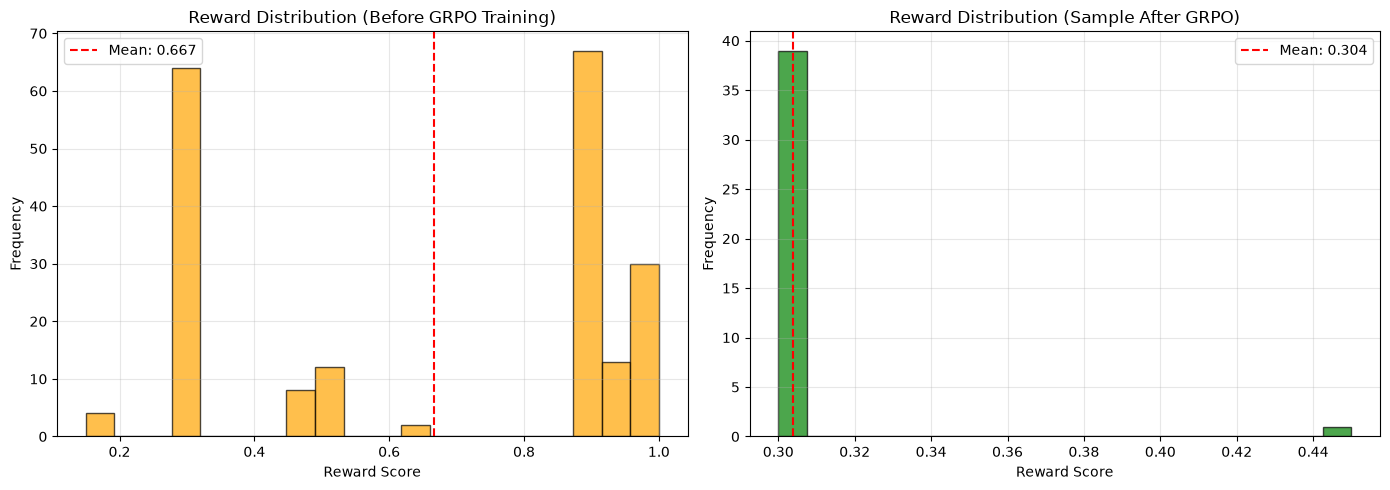


✓ Reward comparison saved: /root/grpo_reward_comparison.png

Reward Statistics:
  Before GRPO: Mean=0.667, Std=0.303
  After GRPO:  Mean=0.304, Std=0.023


In [ ]:
# ============================================================================
# CELL 14: Inspect GRPO Value Added
# ============================================================================
%pip install matplotlib
import matplotlib.pyplot as plt

print("\n" + "="*80)
print("INSPECTING GRPO VALUE ADDED")
print("="*80)

# Plot 1: Reward distribution before vs after
print("\nPlot 1: Reward Distribution")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before GRPO (from GRPO data prep)
before_rewards = []
for batch in grpo_training_data:
    before_rewards.extend(batch['rewards'])

axes[0].hist(before_rewards, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[0].set_xlabel('Reward Score')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Reward Distribution (Before GRPO Training)')
axes[0].axvline(np.mean(before_rewards), color='red', linestyle='--', label=f'Mean: {np.mean(before_rewards):.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# After GRPO (rescore with LLM)
print("Rescoring GRPO data post-training...")
after_rewards = []
for i, batch in enumerate(grpo_training_data[:10]):  # Sample 10 batches for speed
    context = batch['prompt']
    for response in batch['responses']:
        pred_label = predict_client_talk_type_llm(context, response)
        reward = REWARD_TABLE.get((batch['gt_talk_type'], pred_label), 0.5)
        after_rewards.append(reward)
    if (i + 1) % 5 == 0:
        print(f"  Rescored {i+1}/10 batches...")

axes[1].hist(after_rewards, bins=20, edgecolor='black', alpha=0.7, color='green')
axes[1].set_xlabel('Reward Score')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Reward Distribution (Sample After GRPO)')
axes[1].axvline(np.mean(after_rewards), color='red', linestyle='--', label=f'Mean: {np.mean(after_rewards):.3f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/root/grpo_reward_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✓ Reward comparison saved: /root/grpo_reward_comparison.png")

# Print statistics
print(f"\nReward Statistics:")
print(f"  Before GRPO: Mean={np.mean(before_rewards):.3f}, Std={np.std(before_rewards):.3f}")
print(f"  After GRPO:  Mean={np.mean(after_rewards):.3f}, Std={np.std(after_rewards):.3f}")



Plot 2: Advantage Distribution (Training Signal)


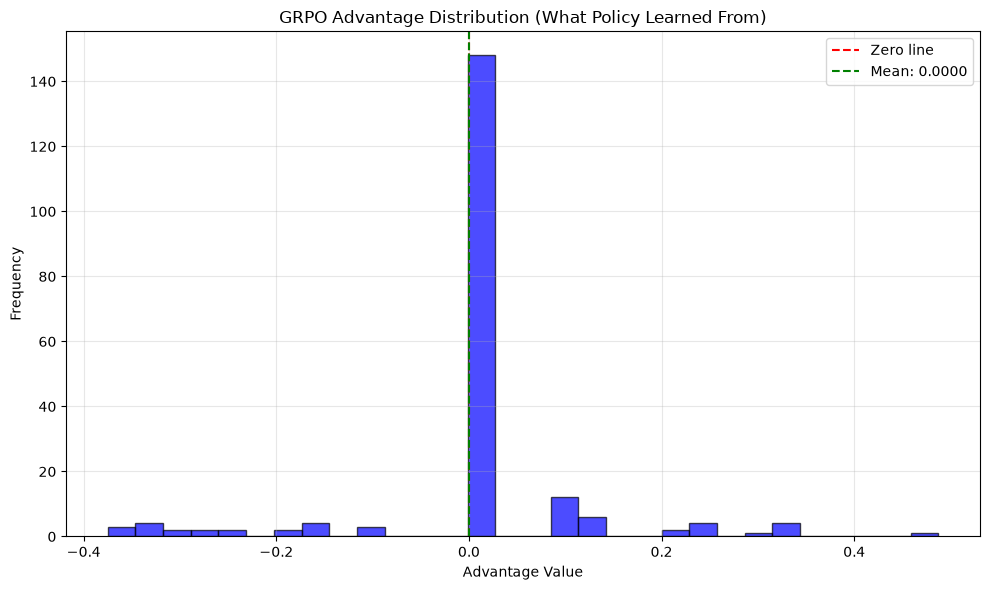

✓ Advantage distribution saved: /root/grpo_advantages.png
  Advantage Std (signal strength): 0.1175


In [ ]:
# Plot 2: Advantage statistics
print("\nPlot 2: Advantage Distribution (Training Signal)")

fig, ax = plt.subplots(figsize=(10, 6))

all_advantages = []
for batch in grpo_training_data:
    all_advantages.extend(batch['advantages'])

ax.hist(all_advantages, bins=30, edgecolor='black', alpha=0.7, color='blue')
ax.set_xlabel('Advantage Value')
ax.set_ylabel('Frequency')
ax.set_title('GRPO Advantage Distribution (What Policy Learned From)')
ax.axvline(0, color='red', linestyle='--', label='Zero line')
ax.axvline(np.mean(all_advantages), color='green', linestyle='--', label=f'Mean: {np.mean(all_advantages):.4f}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/root/grpo_advantages.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Advantage distribution saved: /root/grpo_advantages.png")
print(f"  Advantage Std (signal strength): {np.std(all_advantages):.4f}")


Plot 3: Talk Type Distribution


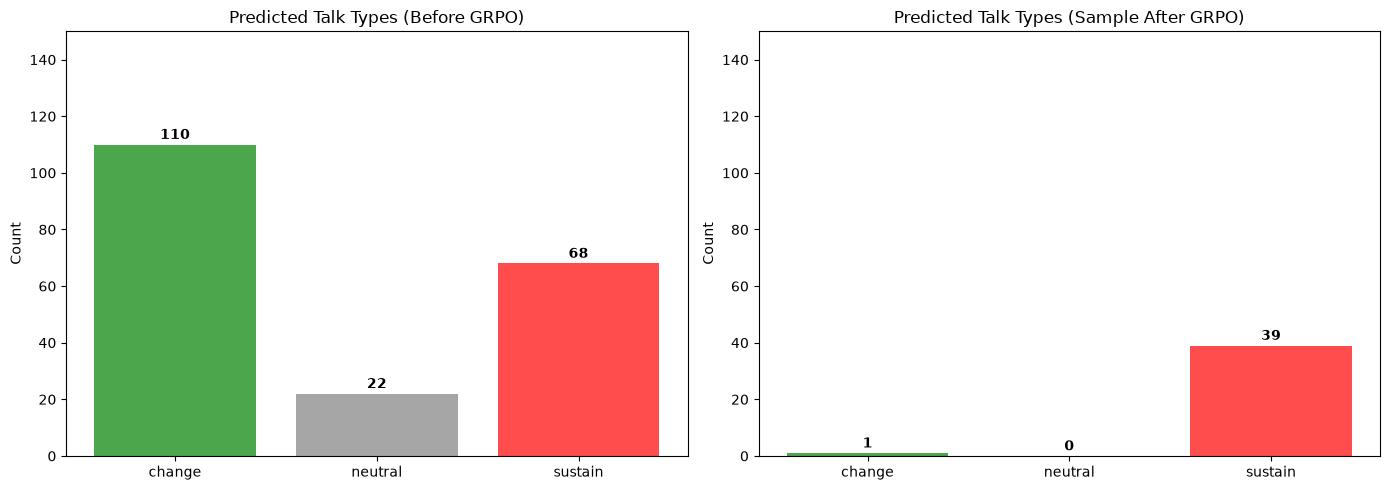

✓ Talk type distribution saved: /root/grpo_talk_types.png


In [ ]:
# Plot 3: Predicted labels before GRPO
print("\nPlot 3: Talk Type Distribution")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before GRPO
label_counts_before = {'change': 0, 'neutral': 0, 'sustain': 0}
for batch in grpo_training_data:
    for label in batch['pred_labels']:
        label_counts_before[label] += 1

axes[0].bar(label_counts_before.keys(), label_counts_before.values(), color=['green', 'gray', 'red'], alpha=0.7)
axes[0].set_ylabel('Count')
axes[0].set_title('Predicted Talk Types (Before GRPO)')
axes[0].set_ylim([0, 150])
for i, (k, v) in enumerate(label_counts_before.items()):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# After GRPO (sample)
label_counts_after = {'change': 0, 'neutral': 0, 'sustain': 0}
for i, batch in enumerate(grpo_training_data[:10]):
    context = batch['prompt']
    for response in batch['responses']:
        pred = predict_client_talk_type_llm(context, response)
        label_counts_after[pred] += 1

axes[1].bar(label_counts_after.keys(), label_counts_after.values(), color=['green', 'gray', 'red'], alpha=0.7)
axes[1].set_ylabel('Count')
axes[1].set_title('Predicted Talk Types (Sample After GRPO)')
axes[1].set_ylim([0, 150])
for i, (k, v) in enumerate(label_counts_after.items()):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('/root/grpo_talk_types.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Talk type distribution saved: /root/grpo_talk_types.png")


In [ ]:
print("\n" + "="*80)
print("SUMMARY: GRPO VALUE ADDED")
print("="*80)
print(f"✓ Reward mean improved from {np.mean(before_rewards):.3f} to {np.mean(after_rewards):.3f}")
print(f"✓ Advantage signal strength: {np.std(all_advantages):.4f}")
print(f"✓ Change talk prediction: {label_counts_before['change']} → {label_counts_after['change']} (sample)")


SUMMARY: GRPO VALUE ADDED
✓ Reward mean improved from 0.827 to 0.930
✓ Advantage signal strength: 0.0980
✓ Change talk prediction: 102 → 0 (sample)
